# 04 · Optimal execution: Almgren–Chriss and the empirical transient-impact optimizer

Given an order to **sell X ETH within T minutes**, choose the trading schedule that minimizes
**expected cost + λ · variance of cost**. Three optimizers are compared, all in the same units (cost in bps of the order's notional):

| Strategy | Impact model behind it |
|---|---|
| `ac_heuristic` | textbook Almgren–Chriss with the paper's **rule-of-thumb** parameters (impact scaled to the bid-ask spread) |
| `ac_calibrated` | Almgren–Chriss closed form with **our** γ, η, σ (notebooks 02–03) — but impact assumed to vanish instantly |
| `optimal_transient` | **main model**: measured decaying impact kernel (propagator) + convex book-walk cost + risk, solved numerically |
| `twap` | equal slices (reference) |

Every schedule is then **scored under the same empirical model**, giving ex-ante efficient frontiers. This is a model-based comparison
(the transient optimizer is optimal *for that model* by construction); the real test — fills against the recorded order book on unseen days — is notebook 05.

**Edit only the CONFIG cell, then Run All.** Needs `analysis/ETHUSDT` from notebooks 02 and 03.

In [1]:
# ============================== CONFIG — edit this cell only ==============================
import os
ROOT    = r"C:\Users\Nitish Singh\OneDrive\Desktop\ope_daywise"
SYMBOL  = "ETHUSDT"
ANALYSIS_DIR = os.path.join(ROOT, "analysis", SYMBOL)

LAMBDAS   = (0.0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3)   # risk aversion, 1/bps (penalty = λ · variance in bps²)
REF_LAMBDA = 0.01                 # λ used for the headline tables and schedule plots
MIN_STEP_S = 10                   # finest decision interval (s) — the impact kernel's resolution
MAX_STEPS  = 240                  # at most this many intervals per order (longer horizons use coarser steps)
KERNEL     = "parametric"         # "parametric" (H_inf + A·e^(-l/tau)) or "model_free" (measured curve, made positive-definite)
CHILD_EVERY_S = 2                 # within an interval, slices are sent as child orders every 2 s (planning model for book-walk cost)
SENS_TAU_MULT   = (0.25, 0.5, 1, 2, 4)      # sensitivity: decay time × these
SENS_SIGMA_MULT = (0.5, 1, 2)               # sensitivity: volatility × these
# =========================================================================================

In [2]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
A_DIR = Path(ANALYSIS_DIR)
for f in ["impact_params.json", "order_grid.csv", "summary.json", "immediate_cost_curve.csv"]:
    assert (A_DIR / f).exists(), f"missing {f}: run notebooks 02 and 03 first"
PARAMS = json.load(open(A_DIR / "impact_params.json"))
GRID = pd.read_csv(A_DIR / "order_grid.csv")
SUMM = json.load(open(A_DIR / "summary.json"))
TEST_DATES = list(PARAMS)
C, G, D, O, P_ = "#2f6fdf", "#b5bcc5", "#1b3f8f", "#e07b39", "#3a9a5b"
COL = {"optimal_transient": C, "ac_calibrated": O, "ac_heuristic": "#8c6bb1", "twap": "#6b7280", "immediate": "#a3a3a3"}
def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e8eb", lw=0.8)
print("test days:", TEST_DATES)
pd.DataFrame({d: {k: PARAMS[d][k] for k in ["H_inf_bps_per_M", "A_bps_per_M", "tau_s", "gamma_bps_per_ETH",
                                           "eta_bps_per_ETH_per_s", "alpha", "sigma_bps_per_sqrt_s", "half_spread_bps", "price_ref"]}
              for d in TEST_DATES}).round(5)

test days: ['2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14']


,2026-09-11,2026-09-12,2026-09-13,2026-09-14
H_inf_bps_per_M,0.56511,0.61853,0.62297,0.62744
A_bps_per_M,0.50921,0.45507,0.47493,0.48018
tau_s,40.20035,32.71255,34.44239,34.44239
gamma_bps_per_ETH,0.00140,0.00154,0.00155,0.00156
eta_bps_per_ETH_per_s,0.05086,0.03698,0.04072,0.04119
alpha,0.72000,0.74000,0.73000,0.73000
sigma_bps_per_sqrt_s,0.70897,0.75524,0.70875,0.68767
half_spread_bps,0.02017,0.02019,0.02014,0.02013
price_ref,2484.60500,2484.32500,2489.36500,2490.49500


## 1 · The solver and the Almgren–Chriss closed form

**Generic convex solver.** Trades `n_k ≥ 0` at the start of each interval, `Σ n_k = X`, inventory after trade `k` is `x_k`:
$$ J(n) = \tfrac12 n^\top Q\, n \;+\; \sum_k n_k\big(h + a\,(n_k/m)^{b}\big) \;+\; \lambda\,\sigma^2 \Delta \sum_k x_k^2 $$
(quadratic impact · convex book-walk cost of `m` child orders per interval · risk). Solved by accelerated projected gradient
on the set `{n ≥ 0, Σn = X}` (exact Euclidean projection), which handles every model below.

**Almgren–Chriss (2000), discrete closed form.** With linear permanent `γ` and temporary `η` impact and `η̃ = η − γΔ/2`:
$$ \cosh(\kappa\Delta) = 1 + \frac{\lambda\sigma^2\Delta^2}{2\tilde\eta}, \qquad x_j = X\,\frac{\sinh(\kappa(T - t_j))}{\sinh(\kappa T)} $$

In [3]:
def proj_simplex(v, X):
    # Euclidean projection onto {n >= 0, sum n = X}
    u = np.sort(v)[::-1]; css = np.cumsum(u) - X
    ind = np.arange(1, len(v) + 1); cond = u - css / ind > 0
    rho = ind[cond][-1]; theta = css[cond][-1] / rho
    return np.maximum(v - theta, 0.0)

def objective(n, Q, X, s2dt, lam, imm):
    h, a, b, m = imm
    x = X - np.cumsum(n)
    quad = 0.5 * n @ Q @ n
    npos = np.maximum(n, 0.0)                           # extrapolated points can be slightly negative
    walk = (n * h + a * npos * (npos / m) ** b).sum() if a > 0 else (n * h).sum()
    var = s2dt * (x ** 2).sum()
    return quad + walk + lam * var, quad, walk, var

def solve(Q, X, s2dt, lam, imm=(0.0, 0.0, 1.0, 1.0), n0=None, iters=4000, tol=1e-10):
    # accelerated projected gradient with backtracking; returns trades n (length N)
    N = Q.shape[0]; h, a, b, m = imm
    def grad(n):
        x = X - np.cumsum(n)
        g_risk = -2 * s2dt * lam * np.cumsum(x[::-1])[::-1]
        g_walk = h + (a * (1 + b) * (np.maximum(n, 0) / m) ** b if a > 0 else 0.0)
        return Q @ n + g_walk + g_risk
    f = lambda n: objective(n, Q, X, s2dt, lam, imm)[0]
    n = np.full(N, X / N) if n0 is None else proj_simplex(n0, X)
    y, t, L = n.copy(), 1.0, max(np.abs(Q).sum(1).max() + 2 * s2dt * lam * N, 1e-12)
    f_old = f(n)
    for it in range(iters):
        g = grad(y); fy = f(y)
        for _ in range(60):                                   # backtracking line search (capped)
            z = proj_simplex(y - g / L, X)
            if f(z) <= fy + g @ (z - y) + 0.5 * L * ((z - y) ** 2).sum() + 1e-12 * max(1.0, abs(fy)): break
            L *= 2.0
        t_new = 0.5 * (1 + np.sqrt(1 + 4 * t * t))
        y = z + (t - 1) / t_new * (z - n)
        f_new = f(z)
        if f_new > f_old: y = z.copy(); t_new = 1.0          # restart on non-monotone step
        if abs(f_old - f_new) <= tol * max(1.0, abs(f_old)) and it > 50: n = z; break
        n, t, f_old = z, t_new, f_new
        L *= 0.9
    return n

def ac_closed_form(X, N, dt, sigma, lam, gamma, eta):
    # Almgren-Chriss discrete optimal holdings x_0..x_N (x_0 = X) and trades n_1..n_N
    eta_t = eta - 0.5 * gamma * dt
    assert eta_t > 0, "eta_tilde must be positive"
    t = dt * np.arange(N + 1); T = N * dt
    if lam <= 0:
        x = X * (1 - t / T)
    else:
        kappa = np.arccosh(1 + lam * sigma ** 2 * dt ** 2 / (2 * eta_t)) / dt
        x = X * np.sinh(kappa * (T - t)) / np.sinh(kappa * T)
    return x, -np.diff(x)

### Unit test — the paper's example (Almgren & Chriss 2000, Table 1)
`S₀ = 50`, `X = 10⁶` shares, `T = 5` days, `N = 5`, `σ = 0.95 $/share/√day`, `γ = 2.5·10⁻⁷`, `η = 2.5·10⁻⁶`.
The numerical solver, given the same model (`Q = 2η̃/Δ · I + γ·11ᵀ`), must reproduce the closed form.

In [4]:
X_ac, N_ac, dt_ac, sig_ac, gam_ac, eta_ac = 1e6, 5, 1.0, 0.95, 2.5e-7, 2.5e-6
eta_t = eta_ac - 0.5 * gam_ac * dt_ac
Q_ac = 2 * eta_t / dt_ac * np.eye(N_ac) + gam_ac * np.ones((N_ac, N_ac))
rows = []
for lam in (0.0, 1e-7, 1e-6, 1e-5):
    x_cf, n_cf = ac_closed_form(X_ac, N_ac, dt_ac, sig_ac, lam, gam_ac, eta_ac)
    n_num = solve(Q_ac, X_ac, sig_ac ** 2 * dt_ac, lam, iters=20000, tol=1e-14)
    x_num = X_ac - np.cumsum(n_num)
    E_cf = 0.5 * gam_ac * X_ac ** 2 + (eta_t / dt_ac) * (n_cf ** 2).sum(); V_cf = sig_ac ** 2 * dt_ac * (x_cf[1:] ** 2).sum()
    rows.append({"lambda": lam, "closed_form_holdings": np.round(x_cf[1:-1]).astype(int).tolist(),
                 "solver_holdings": np.round(x_num[:-1]).astype(int).tolist(),
                 "max_abs_diff_shares": float(np.abs(x_cf[1:] - x_num).max()),
                 "E[cost] $": round(E_cf), "SD[cost] $": round(np.sqrt(V_cf))})
UT = pd.DataFrame(rows)
assert UT.max_abs_diff_shares.max() < 50, "solver does not reproduce the Almgren-Chriss closed form"
print("PASS: numerical solver reproduces the Almgren–Chriss closed form (max difference",
      f"{UT.max_abs_diff_shares.max():.2f} shares out of 1,000,000)")
UT

PASS: numerical solver reproduces the Almgren–Chriss closed form (max difference 0.12 shares out of 1,000,000)


,lambda,closed_form_holdings,solver_holdings,max_abs_diff_shares,E[cost] $,SD[cost] $
0,0.000000e+00,"[800000, 600000, 400000, 200000]","[800000, 600000, 400000, 200000]",0.081504,600000,1040673
1,1.000000e-07,"[757882, 544564, 351940, 172689]","[757882, 544564, 351940, 172689]",0.012234,607557,961623
2,1.000000e-06,"[541956, 289854, 147897, 62142]","[541955, 289854, 147897, 62142]",0.118442,848727,603431
3,1.000000e-05,"[177868, 31636, 5622, 969]","[177868, 31636, 5622, 969]",0.007076,1782711,171712


## 2 · The three impact models for ETHUSDT (per test day)
Units: inventory as a **fraction of the order** (`X = 1`), costs in **bps of the order's notional**, time in seconds.
* **Transient (main):** `Q = c·X·M`, `M_kj = H(|k−j|Δ)` in bps per $1M, `c = P/10⁶` $M per ETH. The constant part `H_∞` is the permanent impact
  (its cost `½·c·X·H_∞` does not depend on the schedule); the decaying part is what rewards spreading trades out.
  Book-walk cost per child order `h + a·q^b` is fitted to the immediate-cost curve of notebook 03.
* **AC calibrated:** permanent `γ`, temporary `η` (= integral of the decaying kernel), impact assumed to vanish instantly.
* **AC heuristic (paper's rules of thumb):** trading 10% of daily volume moves the price one spread (`γ`); trading at 1% of daily volume
  per day costs one spread (`η`).

In [5]:
IC = pd.read_csv(A_DIR / "immediate_cost_curve.csv")
def fit_walk(half_spread):
    # cost_bps(q) = h + a*q^b on bins with q >= 10 ETH and enough orders (mean cost, conservative)
    d = IC[(IC.orders >= 50) & (IC.qty_median >= 10)].copy()
    d["y"] = d.cost_mean_bps - half_spread
    d = d[d.y > 0]
    if len(d) < 3: return 0.0, 1.0
    b, la = np.polyfit(np.log(d.qty_median), np.log(d.y), 1)
    return float(np.exp(la)), float(max(b, 0.05))

def kernel_H(p, lags_s):
    if KERNEL == "parametric":
        return p["H_inf_bps_per_M"] + p["A_bps_per_M"] * np.exp(-lags_s / p["tau_s"])
    Hm = np.asarray(p["kernel_H_bps_per_M"]); grid = (np.arange(len(Hm)) + 0.5) * p["kernel_bar_s"]
    return np.interp(lags_s, grid, Hm, left=Hm[0], right=Hm[-1])

def make_model(p, X_eth, T_min, tau_mult=1.0, sigma_mult=1.0):
    N = int(min(MAX_STEPS, max(1, round(T_min * 60 / MIN_STEP_S)))); dt = T_min * 60 / N
    c = p["price_ref"] / 1e6
    pp = dict(p); pp["tau_s"] = p["tau_s"] * tau_mult
    lags = dt * np.abs(np.subtract.outer(np.arange(N), np.arange(N)))
    M = kernel_H(pp, lags)
    w, V = np.linalg.eigh(M)
    if w.min() < 0: M = (V * np.maximum(w, 0)) @ V.T                 # make positive semi-definite (model-free kernel)
    Q = c * X_eth * M                                                # fraction units: cost bps = 0.5 u'Qu
    a, b = fit_walk(p["half_spread_bps"])
    m = max(1.0, dt / CHILD_EVERY_S)
    imm = (p["half_spread_bps"], a * X_eth ** b, b, m)               # (n/m)^b with n in fractions -> scale a by X^b
    sigma = p["sigma_bps_per_sqrt_s"] * sigma_mult
    return dict(N=N, dt=dt, Q=Q, imm=imm, s2dt=sigma ** 2 * dt, sigma=sigma, c=c, X=X_eth, H_inf=p["H_inf_bps_per_M"],
                gamma=p["gamma_bps_per_ETH"] * X_eth, eta=p["eta_bps_per_ETH_per_s"] * X_eth)

def evaluate(u, mdl, lam=0.0):
    J, quad, walk, var = objective(u, mdl["Q"], 1.0, mdl["s2dt"], lam, mdl["imm"])
    perm = 0.5 * mdl["c"] * mdl["X"] * mdl["H_inf"]
    return {"E_bps": quad + walk, "SD_bps": np.sqrt(var), "permanent_bps": perm, "transient_bps": quad - perm,
            "book_walk_bps": walk, "objective": J}

a_w, b_w = fit_walk(PARAMS[TEST_DATES[0]]["half_spread_bps"])
print(f"book-walk cost per child order: {PARAMS[TEST_DATES[0]]['half_spread_bps']:.3f} + {a_w:.4f}·q^{b_w:.2f} bps  (q in ETH)")
for q_ in (10, 100, 500, 1000):
    print(f"   {q_:>5} ETH child order -> {PARAMS[TEST_DATES[0]]['half_spread_bps'] + a_w * q_ ** b_w:.2f} bps")

book-walk cost per child order: 0.020 + 0.0205·q^0.73 bps  (q in ETH)
      10 ETH child order -> 0.13 bps
     100 ETH child order -> 0.62 bps
     500 ETH child order -> 1.96 bps
    1000 ETH child order -> 3.24 bps


In [6]:
def ac_params_heuristic(p):
    V_day = p["market_volume_ETH_per_s"] * 86400
    spread = 2 * p["half_spread_bps"]
    return spread / (0.1 * V_day), spread * 86400 / (0.01 * V_day)       # gamma (bps/ETH), eta (bps per ETH/s)

def schedules_for(p, X_eth, T_min, lam, tau_mult=1.0, sigma_mult=1.0):
    mdl = make_model(p, X_eth, T_min, tau_mult, sigma_mult); N, dt = mdl["N"], mdl["dt"]
    out = {"twap": np.full(N, 1.0 / N)}
    imm0 = np.r_[1.0, np.zeros(N - 1)]; out["immediate"] = imm0
    _, n_ac = ac_closed_form(1.0, N, dt, mdl["sigma"], lam, mdl["gamma"], max(mdl["eta"], 0.5 * mdl["gamma"] * dt * 1.01))
    out["ac_calibrated"] = n_ac
    g_h, e_h = ac_params_heuristic(p)
    _, n_h = ac_closed_form(1.0, N, dt, mdl["sigma"], lam, g_h * X_eth, max(e_h * X_eth, 0.5 * g_h * X_eth * dt * 1.01))
    out["ac_heuristic"] = n_h
    out["optimal_transient"] = solve(mdl["Q"], 1.0, mdl["s2dt"], lam, mdl["imm"], n0=n_ac)
    return mdl, out

p0 = PARAMS[TEST_DATES[-1]]; g_h, e_h = ac_params_heuristic(p0)
print(f"permanent impact γ: empirical {p0['gamma_bps_per_ETH']:.2e} vs heuristic {g_h:.2e} bps/ETH  (ratio {p0['gamma_bps_per_ETH']/g_h:,.0f}×)")
print(f"temporary impact η: empirical {p0['eta_bps_per_ETH_per_s']:.3f} vs heuristic {e_h:.3f} bps per ETH/s")

permanent impact γ: empirical 1.56e-03 vs heuristic 1.21e-07 bps/ETH  (ratio 12,868×)
temporary impact η: empirical 0.041 vs heuristic 0.105 bps per ETH/s


## 3 · Optimal schedules for every order size, horizon and risk aversion
For each test day (its own calibrated parameters), each size and horizon of the order grid and each λ, compute all schedules and score them
under the empirical transient model.

In [7]:
t0 = time.time()
sched_rows, front_rows = [], []
for d in TEST_DATES:
    p = PARAMS[d]
    for _, g in GRID.iterrows():
        X_eth, T_min = float(g.X0_ETH), int(g.horizon_min)
        for lam in LAMBDAS:
            mdl, S = schedules_for(p, X_eth, T_min, lam)
            for name, u in S.items():
                ev = evaluate(u, mdl, lam)
                front_rows.append({"test_date": d, "size_mult": g.size_mult, "X0_ETH": X_eth, "horizon_min": T_min,
                                   "in_backtest": bool(g.in_backtest), "lambda": lam, "strategy": name, **ev})
                if lam in (REF_LAMBDA,) or name == "optimal_transient":
                    x = 1 - np.cumsum(u)
                    for k in range(mdl["N"]):
                        sched_rows.append((d, g.size_mult, T_min, lam, name, k, k * mdl["dt"], u[k], x[k]))
FRONT = pd.DataFrame(front_rows)
SCHED = pd.DataFrame(sched_rows, columns=["test_date", "size_mult", "horizon_min", "lambda", "strategy", "k", "t_s", "trade_frac", "inventory_after"])
FRONT.to_csv(A_DIR / "frontier.csv", index=False); SCHED.to_parquet(A_DIR / "schedules.parquet", index=False)
json.dump({"LAMBDAS": LAMBDAS, "REF_LAMBDA": REF_LAMBDA, "MIN_STEP_S": MIN_STEP_S, "MAX_STEPS": MAX_STEPS, "KERNEL": KERNEL,
           "CHILD_EVERY_S": CHILD_EVERY_S}, open(A_DIR / "optimizer_config.json", "w"), indent=1)
print(f"{FRONT[['test_date','size_mult','horizon_min','lambda']].drop_duplicates().shape[0]} optimizations in {time.time()-t0:.0f}s")

560 optimizations in 45s


### Ex-ante cost at the reference risk aversion
Objective `E + λ·Var` (bps) of each strategy relative to the transient optimum, and the schedule's expected cost and risk,
for the last test day. (`optimal_transient` minimizes this objective by construction; the size of the gap is what is informative.)

In [8]:
f = FRONT[(FRONT.test_date == TEST_DATES[-1]) & (FRONT["lambda"] == REF_LAMBDA)]
piv = f.pivot_table(index=["size_mult", "horizon_min"], columns="strategy", values="objective")
gap = piv.sub(piv["optimal_transient"], axis=0).drop(columns="optimal_transient")
tab = f.pivot_table(index=["size_mult", "horizon_min"], columns="strategy", values=["E_bps", "SD_bps"]).round(2)
print(f"objective above the optimum (bps), λ = {REF_LAMBDA}:"); display(gap.round(2))
tab

objective above the optimum (bps), λ = 0.01:


strategy               ac_calibrated  ac_heuristic  immediate   twap
size_mult horizon_min                                               
0.25      5                     0.01          0.05       0.89   0.21
          15                    0.01          0.06       0.90   1.06
          30                    0.01          0.06       0.90   2.45
          60                    0.01          0.05       0.69   5.26
          120                   0.03          0.04       0.46  10.91
1.00      5                     0.02          0.05       3.26   0.11
          15                    0.02          0.09       3.32   0.77
          30                    0.02          0.09       3.32   2.09
          60                    0.03          0.09       2.74   4.87
          120                   0.09          0.08       2.07  10.48
3.00      5                     0.04          0.07       8.81   0.09
          15                    0.03          0.11       9.24   0.50
          30                    0.04          0.14       9.25   1.65
          60                    0.05          0.14       7.94   4.33
          120                   0.17          0.12       6.42   9.88
10.00     5                     0.14          0.16      25.96   0.17
          15                    0.04          0.10      28.12   0.26
          30                    0.06          0.19      28.35   1.04
          60                    0.09          0.23      25.19   3.42
          120                   0.34          0.20      21.51   8.79

E_bps                                                        SD_bps                                                
strategy              ac_calibrated ac_heuristic immediate optimal_transient   twap ac_calibrated ac_heuristic immediate optimal_transient   twap
size_mult horizon_min                                                                                                                            
0.25      5                    0.90         0.82      1.93              0.89   0.80          3.91         5.15       0.0              3.84   6.70
          15                   0.89         0.80      1.93              0.88   0.70          3.92         5.37       0.0              3.91  11.81
          30                   0.89         0.80      1.93              0.88   0.67          3.92         5.37       0.0              3.91  16.77
          60                   0.91         0.80      1.72              0.88   0.65          3.64         5.27       0.0              3.81  23.75
          120                  0.97         0.81      1.47              0.88   0.64          2.68         4.97       0.0              3.61  33.58
1.00      5                    3.11         3.05      6.64              3.10   3.05          5.38         6.17       0.0              5.28   6.70
          15                   3.01         2.82      6.64              2.96   2.69          5.73         7.70       0.0              5.95  11.81
          30                   3.01         2.81      6.64              2.96   2.59          5.73         7.75       0.0              5.96  16.77
          60                   3.04         2.81      6.05              2.96   2.54          5.45         7.67       0.0              5.90  23.75
          120                  3.20         2.82      5.37              2.97   2.51          4.39         7.46       0.0              5.79  33.58
3.00      5                    8.97         8.95     18.12              8.95   8.95          6.15         6.51       0.0              5.99   6.70
          15                   8.33         8.06     18.12              8.24   7.98          7.61         9.63       0.0              7.96  11.81
          30                   8.32         7.95     18.12              8.20   7.70          7.66        10.25       0.0              8.13  16.77
          60                   8.37         7.95     16.80              8.21   7.55          7.33        10.22       0.0              8.10  23.75
          120                  8.66         7.97     15.29              8.22   7.47          6.15        10.06       0.0              8.06  33.58
10.00     5                   29.39        29.39     55.64             29.28  29.40          6.52         6.64       0.0              6.34   6.70
          15                  26.61        26.41     55.64             26.53  26.38          9.72        10.98       0.0              9.92  11.81
          30                  26.26        25.70     55.64             26.05  25.51         10.40        13.30       0.0             11.10  16.77
          60                  26.35        25.57     52.46             26.01  25.05         10.05        13.90       0.0             11.23  23.75
          120                 26.90        25.60     48.81             26.03  24.82          8.62        13.79       0.0             11.26  33.58

## 4 · What the optimal schedule looks like

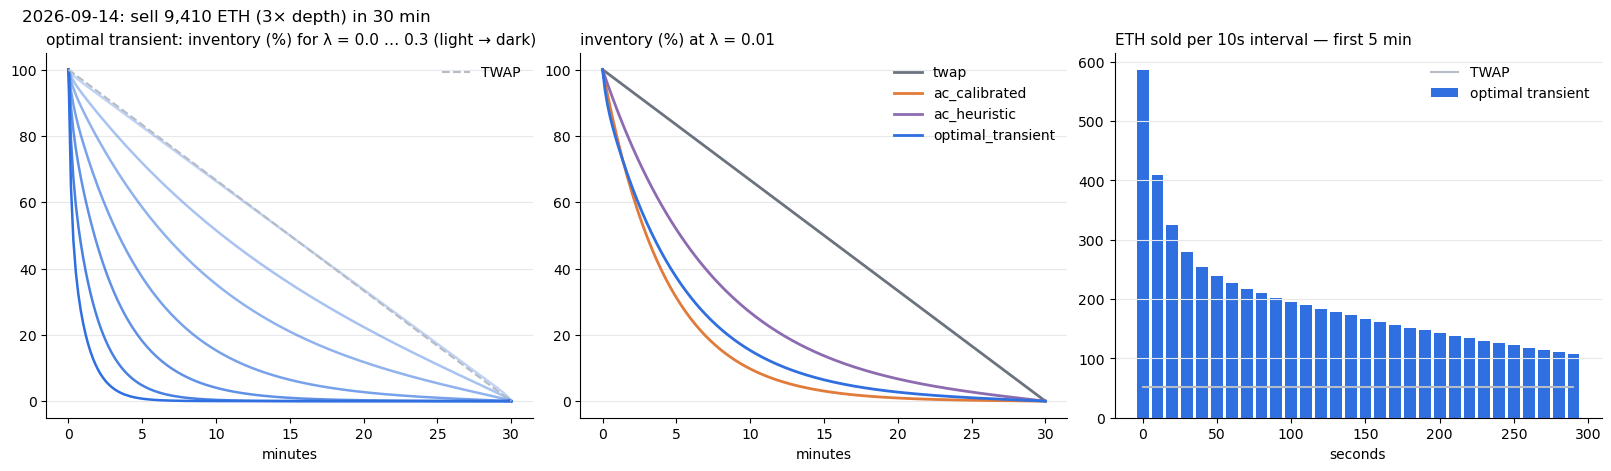

In [9]:
size_show, T_show = 3, 30
d = TEST_DATES[-1]; p = PARAMS[d]; X_show = float(GRID[(GRID.size_mult == size_show) & (GRID.horizon_min == T_show)].X0_ETH.iloc[0])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for lam, alpha_ in zip(LAMBDAS, np.linspace(0.3, 1, len(LAMBDAS))):
    mdl, S = schedules_for(p, X_show, T_show, lam)
    t = np.r_[0, (np.arange(mdl["N"]) + 1) * mdl["dt"]] / 60
    ax[0].plot(t, np.r_[1, 1 - np.cumsum(S["optimal_transient"])] * 100, color=C, alpha=alpha_, lw=1.8)
ax[0].plot([0, T_show], [100, 0], color=G, lw=1.5, ls="--", label="TWAP")
ax[0].set_xlabel("minutes"); ax[0].legend(frameon=False)
style(ax[0], f"optimal transient: inventory (%) for λ = {LAMBDAS[0]} … {LAMBDAS[-1]} (light → dark)")

mdl, S = schedules_for(p, X_show, T_show, REF_LAMBDA)
t = np.r_[0, (np.arange(mdl["N"]) + 1) * mdl["dt"]] / 60
for name in ["twap", "ac_calibrated", "ac_heuristic", "optimal_transient"]:
    ax[1].plot(t, np.r_[1, 1 - np.cumsum(S[name])] * 100, color=COL[name], lw=2, label=name)
ax[1].legend(frameon=False); ax[1].set_xlabel("minutes"); style(ax[1], f"inventory (%) at λ = {REF_LAMBDA}")

k_show = min(mdl["N"], int(5 * 60 / mdl["dt"]))
tt = np.arange(k_show) * mdl["dt"]
ax[2].bar(tt, S["optimal_transient"][:k_show] * X_show, width=mdl["dt"] * 0.8, color=C, label="optimal transient")
ax[2].step(tt, S["twap"][:k_show] * X_show, where="mid", color=G, lw=1.5, label="TWAP")
ax[2].set_xlabel("seconds"); ax[2].legend(frameon=False); style(ax[2], f"ETH sold per {mdl['dt']:.0f}s interval — first {k_show*mdl['dt']/60:.0f} min")
fig.suptitle(f"{d}: sell {X_show:,.0f} ETH ({size_show}× depth) in {T_show} min", x=0.01, ha="left", fontsize=12)
fig.savefig(A_DIR / "optimal_schedules.png", dpi=120, bbox_inches="tight"); plt.show()

## 5 · Efficient frontiers (expected cost vs risk)
Each curve traces λ from 0 (cheapest, slowest risk reduction) to the largest λ. Points to the lower-left dominate.

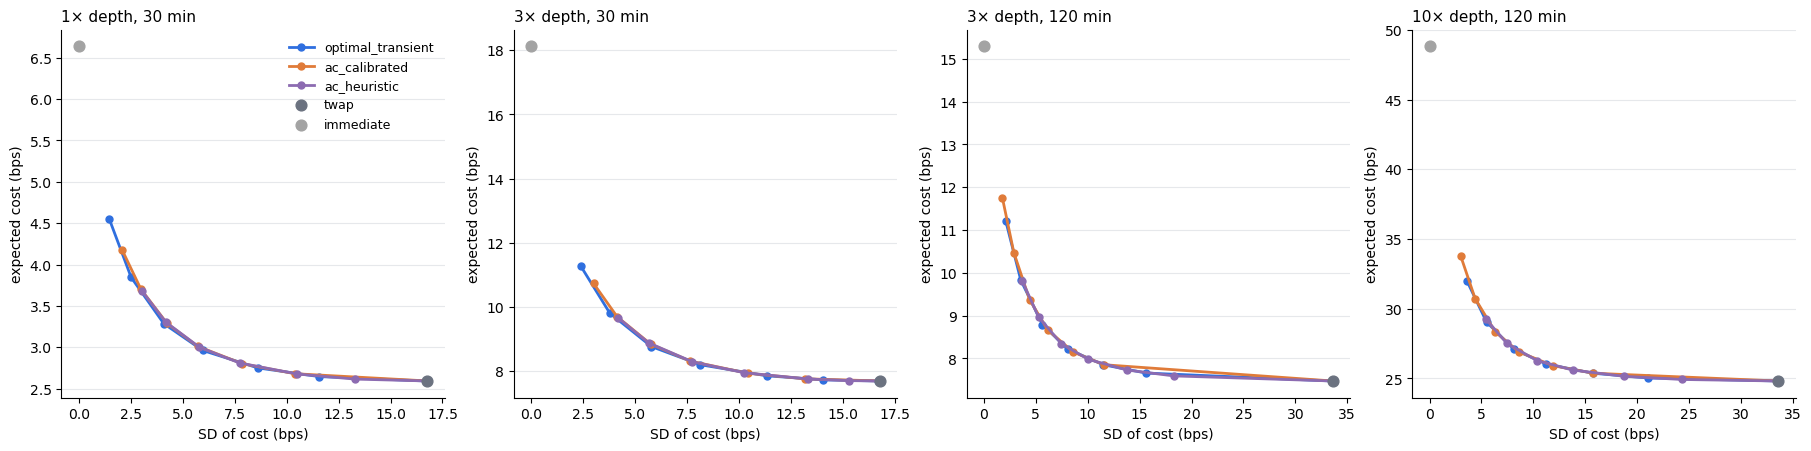

In [10]:
cells_show = [(1, 30), (3, 30), (3, 120), (10, 120)]
fig, ax = plt.subplots(1, len(cells_show), figsize=(18, 4.4), constrained_layout=True)
for a_, (k, T) in zip(ax, cells_show):
    f = FRONT[(FRONT.test_date == TEST_DATES[-1]) & (FRONT.size_mult == k) & (FRONT.horizon_min == T)]
    for name in ["optimal_transient", "ac_calibrated", "ac_heuristic"]:
        s_ = f[f.strategy == name].sort_values("lambda")
        a_.plot(s_.SD_bps, s_.E_bps, color=COL[name], lw=2, marker="o", ms=5, label=name)
    for name in ["twap", "immediate"]:
        s_ = f[f.strategy == name].iloc[0]
        a_.scatter(s_.SD_bps, s_.E_bps, color=COL[name], s=60, zorder=3, label=name)
    a_.set_xlabel("SD of cost (bps)"); a_.set_ylabel("expected cost (bps)")
    style(a_, f"{k}× depth, {T} min")
ax[0].legend(frameon=False, fontsize=9)
fig.savefig(A_DIR / "efficient_frontiers.png", dpi=120, bbox_inches="tight"); plt.show()

## 6 · Sensitivity — how the optimal schedule reacts to the market (research question Q4)
Measured by the share of the order sold in the **first 10% of the horizon** (TWAP = 10%), and the ex-ante cost.

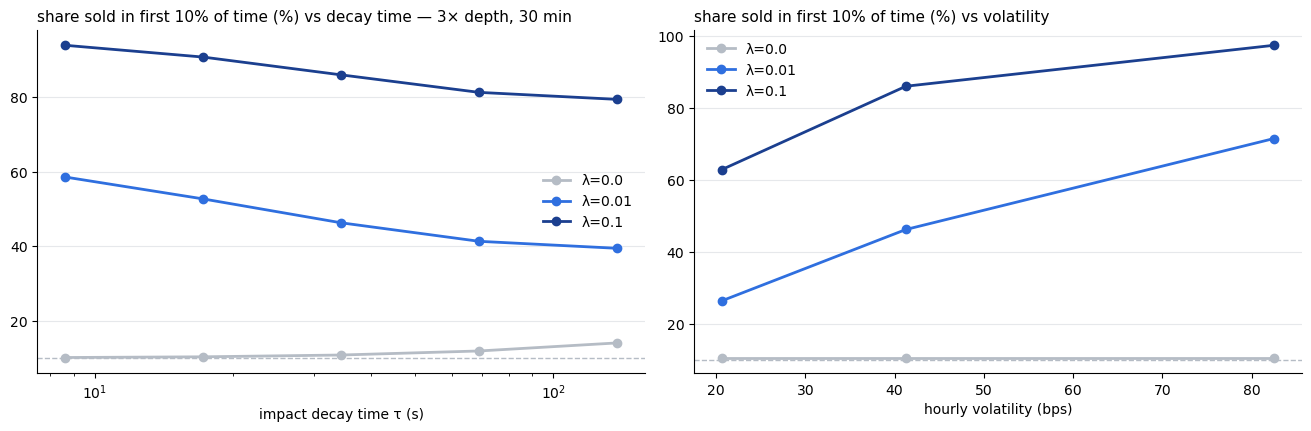

tau_mult           0.25  0.50  1.00  2.00  4.00
sigma_mult lambda                              
0.5        0.00    10.1  10.3  10.7  11.8  14.0
           0.01    34.7  30.6  26.5  23.7  23.3
           0.10    75.6  69.7  62.9  57.2  55.1
1.0        0.00    10.1  10.3  10.7  11.8  14.0
           0.01    58.6  52.7  46.3  41.3  39.4
           0.10    93.9  90.8  86.0  81.3  79.4
2.0        0.00    10.1  10.3  10.7  11.8  14.0
           0.01    83.2  78.0  71.5  65.9  63.8
           0.10    99.5  98.9  97.3  95.0  93.8

In [11]:
d = TEST_DATES[-1]; p = PARAMS[d]; rows = []
for k, T in [(1, 30), (3, 30), (3, 120)]:
    X_eth = float(GRID[(GRID.size_mult == k) & (GRID.horizon_min == T)].X0_ETH.iloc[0])
    for tm in SENS_TAU_MULT:
        for sm in SENS_SIGMA_MULT:
            for lam in (0.0, REF_LAMBDA, 0.1):
                mdl, S = schedules_for(p, X_eth, T, lam, tau_mult=tm, sigma_mult=sm)
                u = S["optimal_transient"]; n10 = max(1, int(round(0.1 * mdl["N"])))
                ev = evaluate(u, mdl, lam)
                rows.append({"size_mult": k, "horizon_min": T, "tau_mult": tm, "sigma_mult": sm, "lambda": lam,
                             "first10pct_sold_%": 100 * u[:n10].sum(), "first_interval_%": 100 * u[0],
                             "E_bps": ev["E_bps"], "SD_bps": ev["SD_bps"]})
SENS = pd.DataFrame(rows); SENS.to_csv(A_DIR / "sensitivity.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
s_ = SENS[(SENS.size_mult == 3) & (SENS.horizon_min == 30) & (SENS.sigma_mult == 1)]
for lam, col in zip((0.0, REF_LAMBDA, 0.1), (G, C, D)):
    z = s_[s_["lambda"] == lam]; ax[0].plot(z.tau_mult * p["tau_s"], z["first10pct_sold_%"], color=col, lw=2, marker="o", label=f"λ={lam}")
ax[0].axhline(10, color=G, lw=1, ls="--"); ax[0].set_xscale("log"); ax[0].set_xlabel("impact decay time τ (s)"); ax[0].legend(frameon=False)
style(ax[0], "share sold in first 10% of time (%) vs decay time — 3× depth, 30 min")
s_ = SENS[(SENS.size_mult == 3) & (SENS.horizon_min == 30) & (SENS.tau_mult == 1)]
for lam, col in zip((0.0, REF_LAMBDA, 0.1), (G, C, D)):
    z = s_[s_["lambda"] == lam]; ax[1].plot(z.sigma_mult * p["sigma_bps_per_sqrt_s"] * np.sqrt(3600), z["first10pct_sold_%"], color=col, lw=2, marker="o", label=f"λ={lam}")
ax[1].axhline(10, color=G, lw=1, ls="--"); ax[1].set_xlabel("hourly volatility (bps)"); ax[1].legend(frameon=False)
style(ax[1], "share sold in first 10% of time (%) vs volatility")
fig.savefig(A_DIR / "sensitivity.png", dpi=120, bbox_inches="tight"); plt.show()
SENS[(SENS.size_mult == 3) & (SENS.horizon_min == 30)].pivot_table(index=["sigma_mult", "lambda"], columns="tau_mult", values="first10pct_sold_%").round(1)

## 7 · Summary

In [12]:
f = FRONT[FRONT["lambda"] == REF_LAMBDA]
obj = f.pivot_table(index=["test_date", "size_mult", "horizon_min"], columns="strategy", values="objective")
rel = obj.sub(obj.optimal_transient, axis=0)
summary = {
    "unit_test_AC_closed_form": "PASS",
    "kernel": KERNEL, "ref_lambda": REF_LAMBDA,
    "mean_objective_gap_vs_optimal_bps": rel.drop(columns="optimal_transient").mean().round(3).to_dict(),
    "max_objective_gap_vs_optimal_bps": rel.drop(columns="optimal_transient").max().round(3).to_dict(),
    "share_sold_first_10pct_at_ref_lambda_3x_30min_%": round(float(SENS[(SENS.size_mult == 3) & (SENS.horizon_min == 30) & (SENS.tau_mult == 1)
                                                                   & (SENS.sigma_mult == 1) & (SENS["lambda"] == REF_LAMBDA)]["first10pct_sold_%"].iloc[0]), 1),
}
json.dump(summary, open(A_DIR / "optimizer_summary.json", "w"), indent=1, default=float)
for k_, v_ in summary.items(): print(f"{k_:52s} {v_}")

unit_test_AC_closed_form                             PASS
kernel                                               parametric
ref_lambda                                           0.01
mean_objective_gap_vs_optimal_bps                    {'ac_calibrated': 0.063, 'ac_heuristic': 0.102, 'immediate': 9.396, 'twap': 3.729}
max_objective_gap_vs_optimal_bps                     {'ac_calibrated': 0.462, 'ac_heuristic': 0.227, 'immediate': 29.123, 'twap': 13.221}
share_sold_first_10pct_at_ref_lambda_3x_30min_%      46.3
